# Coupling of absorption and scattering (3/3): O2 bands

In hGRS 1.2.0 the O2, O4 and CO2 absorption is corrected with the REPTRAN fine table, scaled by an empirical factor
$\kappa$ = 0.35 (`gas_absorption_scattering_coefficient`), along the direct-beam air mass, for the whole signal:

$$ T_{O_2} = \left\langle \exp\left[-\bar M\, \kappa\, \frac{P}{1000}\, (\tau_{O_2} + \tau_{O_4} + \tau_{CO_2})\right] \right\rangle_{band} $$

`radcalnet_oc` found that the REPTRAN table, used as a spectrum at sub-nanometre resolution, makes the O2-B and O2-A
bands too deep (it is a band parameterization), and replaced it by a line-by-line computation (HITRAN), plus the
photon path-length model for the scattered light. hGRS now has both (`o2_model: lbl`, `gas_coupling: path_length`); the
default of hGRS 2.0.0, `o2_model: lbl_o2b`, uses the line-by-line table in the O2-B band only and REPTRAN in the O2-A
band (section 1).

This notebook compares, at the EnMAP bands of the O2-B (686, 693 nm) and O2-A (756, 764, 771 nm) bands:

1. the transmittance models of hGRS (REPTRAN with $\kappa$, line by line, path-length) with SOS-ABS, per term;
2. what $\kappa$ = 0.35 compensates;
3. the sensitivity to the band centre (spectral calibration);
4. the residual O2 features of $R_{rs}$ in the products of both modes.

In [1]:
import warnings
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import coupling_tools as ct
from hgrs.gas_coupling import GasTransmittance

warnings.filterwarnings('ignore')
ct.set_style()
pd.set_option('display.precision', 3)

sos_abs, sos_noabs, tgdir_abs, tgdir_noabs = ct.load_sos()
bands = ct.Bands.enmap_lucinda()
O2_BANDS = [686.32, 693.01, 756.35, 763.70, 771.11]
SZA, VZA, AZI, P, U = 44.5, 15.9, 90., 1009., 2.
M = ct.air_mass(SZA, VZA)
gas = ct.gas_lut(600, 900)
FINE = np.arange(640, 820, 0.005)            # grid of the SOS-ABS and line-by-line transmittances

The O2 windows of the SOS-ABS simulations (684-698 and 757-772 nm) are narrower than an EnMAP band and its wings: the
SOS-ABS transmittances are set to 1 outside the windows before the band average (`ct.on_fine`), which neglects the
weak water vapour absorption of the band wings.

## 1. Transmittance models against SOS-ABS

In [2]:
def sos_terms(aot, sza=SZA):
    a, n = sos_abs.sel(h2o=U), sos_noabs
    r0a, r0n = ct.toa(a, sza, VZA, AZI, albedo=0., aot_ref=aot), ct.toa(n, sza, VZA, AZI, albedo=0., aot_ref=aot)
    r1a, r1n = ct.toa(a, sza, VZA, AZI, albedo=0.1, aot_ref=aot), ct.toa(n, sza, VZA, AZI, albedo=0.1, aot_ref=aot)
    m = ct.air_mass(sza, VZA)
    return {'path': ct.on_fine(r0a / r0n, FINE), 'surface': ct.on_fine((r1a - r0a) / (r1n - r0n), FINE),
            'direct': ct.on_fine(ct.tg_direct(tgdir_abs, tgdir_noabs, m, U), FINE)}

gt_lbl = GasTransmittance(gas, 0.35, coupling='path_length', o2_model='lbl')     # hgrs.gas_coupling
gt_rep = GasTransmittance(gas, 0.35, coupling='decoupled', o2_model='reptran')
o2 = lambda gt, term, aot: gt.other_gases(term, M, P, 0., 0., 0., aot550=aot)  # O2, O4, CO2 (other gases set to 0)
avg = lambda t, wl: bands.average(t, wl, O2_BANDS)

rows = {}
for aot in (0.05, 0.15, 0.4):
    s = sos_terms(aot)
    rows[f'SOS-ABS path, AOT {aot}'] = avg(s['path'], FINE)
    if aot == 0.15:
        rows['SOS-ABS surface, AOT 0.15'] = avg(s['surface'], FINE)
        rows['SOS-ABS direct beam'] = avg(s['direct'], FINE)
for kappa in (0.35, 1.):
    g = GasTransmittance(gas, kappa, coupling='decoupled', o2_model='reptran')
    rows[f'hGRS REPTRAN kappa={kappa} (1.2.0: kappa 0.35)'] = avg(o2(g, 'dir', 0.1), gas.wl.values)
rows['hGRS line by line, direct beam'] = avg(o2(gt_lbl, 'dir', 0.1), gas.wl.values)
for aot in (0.05, 0.15):
    rows[f'hGRS line by line + path length, path, AOT {aot}'] = avg(o2(gt_lbl, 'atm', aot), gas.wl.values)
rows['hGRS line by line + path length, water-leaving'] = avg(o2(gt_lbl, 'w', 0.15), gas.wl.values)
tab = pd.DataFrame(rows, index=[f'{b:.1f}' for b in O2_BANDS]).T.rename_axis(columns=f'band (nm), m = {M:.2f}')
tab

"band (nm), m = 2.44",686.3,693.0,756.4,763.7,771.1
"SOS-ABS path, AOT 0.05",0.911,0.917,0.898,0.718,0.948
"SOS-ABS path, AOT 0.15",0.900,0.904,0.887,0.684,0.938
"SOS-ABS surface, AOT 0.15",0.875,0.867,0.860,0.599,0.923
SOS-ABS direct beam,0.878,0.871,0.861,0.603,0.924
"SOS-ABS path, AOT 0.4",0.887,0.888,0.876,0.650,0.930
hGRS REPTRAN kappa=0.35 (1.2.0: kappa 0.35),0.891,0.926,0.876,0.645,0.932
hGRS REPTRAN kappa=1.0 (1.2.0: kappa 0.35),0.826,0.872,0.845,0.534,0.898
"hGRS line by line, direct beam",0.903,0.930,0.866,0.621,0.926
"hGRS line by line + path length, path, AOT 0.05",0.932,0.952,0.901,0.725,0.948
"hGRS line by line + path length, path, AOT 0.15",0.927,0.949,0.895,0.706,0.944


Notes on the table (two-way air mass 2.44):

* along the direct beam the line-by-line O2 of hGRS is close to SOS-ABS (CKD) in the O2-A band (0.621 against
  0.603 at 764 nm), and REPTRAN without $\kappa$ is much too absorbing (0.534);
* the path term of SOS-ABS is less absorbed than the direct beam and depends on the aerosol load (0.65-0.72 at
  764 nm); the line-by-line + path-length model of hGRS reproduces it within 3 % (0.725 and 0.706 for AOT 0.05 and
  0.15); in the O2-B band the line-by-line model is about 2 % less absorbing than the CKD of SOS-ABS;
* at 764 nm, $\kappa$ = 0.35 on REPTRAN gives a transmittance (0.645) between those of the path term and of the
  surface term: an average correction of the too deep REPTRAN band and of the coupling, right for one share of
  path reflectance only (at 693 nm it is less absorbing than both).

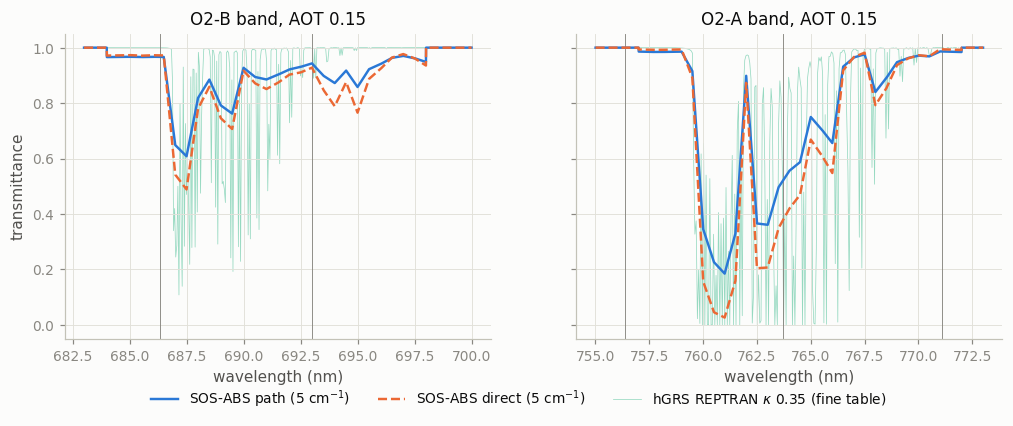

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
s = sos_terms(0.15)
t_dir_lbl = o2(gt_lbl, 'dir', 0.15); t_atm_lbl = o2(gt_lbl, 'atm', 0.15)
t_rep = o2(GasTransmittance(gas, 0.35, coupling='decoupled', o2_model='reptran'), 'dir', 0.1)
for ax, (lo, hi, name) in zip(axes, [(683, 700, 'O2-B'), (755, 773, 'O2-A')]):
    for i, (lab, wl, t) in enumerate([('SOS-ABS path (5 cm$^{-1}$)', FINE, s['path']),
                                      ('SOS-ABS direct (5 cm$^{-1}$)', FINE, s['direct']),
                                      ('hGRS REPTRAN $\\kappa$ 0.35 (fine table)', gas.wl.values, t_rep)]):
        k = (wl >= lo) & (wl <= hi)
        fine_table = i == 2
        ax.plot(wl[k], t[k], color=ct.COLORS[i], linestyle='-' if fine_table else ct.STYLES[i],
                lw=0.5 if fine_table else 1.6, alpha=0.45 if fine_table else 1, zorder=1 if fine_table else 3, label=lab)
    for j, c in enumerate([b for b in O2_BANDS if lo < b < hi]):
        ax.axvline(c, color=ct.MUTED, lw=0.6)
    ax.set_title(f'{name} band, AOT 0.15'); ax.set_xlabel('wavelength (nm)')
axes[0].set_ylabel('transmittance')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.1))
plt.show()

(Vertical lines: centres of the EnMAP bands. The SOS-ABS curves are averages over 5 cm$^{-1}$ CKD intervals, the
REPTRAN curve is the fine table of hGRS: their depths are not comparable channel by channel, only after the band
average of the table above.)

## 2. What $\kappa$ = 0.35 compensates

$\kappa$ that makes the REPTRAN model match each SOS-ABS term at 764 nm, for the solar angles and aerosol loads of
the simulations:

In [4]:
kappas = np.linspace(0.05, 1.2, 116)
rep_curve = {}
rows = []
for sza in (40., 55., 70.):
    m = ct.air_mass(sza, VZA)
    t_k = np.array([bands.average(np.exp(-m * k * (gas.o2 + gas.o4 + gas.co2).values * P / 1000), gas.wl.values, [763.70])[0]
                    for k in kappas])
    for aot in (0.05, 0.15, 0.4):
        s = sos_terms(aot, sza)
        for term in ('path', 'surface'):
            t_sos = bands.average(s[term], FINE, [763.70])[0]
            rows.append(dict(sza=sza, aot=aot, term=term, T_sos=t_sos, kappa=np.interp(t_sos, t_k[::-1], kappas[::-1])))
kap = pd.DataFrame(rows)
kap.pivot_table(index=['term', 'sza'], columns='aot', values='kappa').rename_axis(columns='kappa matching SOS-ABS at 764 nm, AOT:')

kappa matching SOS-ABS at 764 nm, AOT:   0.05   0.15   0.40
term    sza                                                
path    40.0                            0.161  0.229  0.324
        55.0                            0.162  0.240  0.352
        70.0                            0.210  0.281  0.366
surface 40.0                            0.533  0.540  0.555
        55.0                            0.549  0.557  0.574
        70.0                            0.581  0.588  0.597

The $\kappa$ that would be right is 0.53-0.60 for the surface term and 0.16-0.37 for the path reflectance,
depending on the aerosol load and the solar angle: a single factor cannot be right for both terms, which is why hGRS
now separates them.

## 3. Sensitivity to the band centre

The O2-A band is narrow and steep: the band transmittance depends on the exact centre and width of the band
(spectral calibration, smile). Direct-beam line-by-line transmittance at 764 nm for shifted centres:

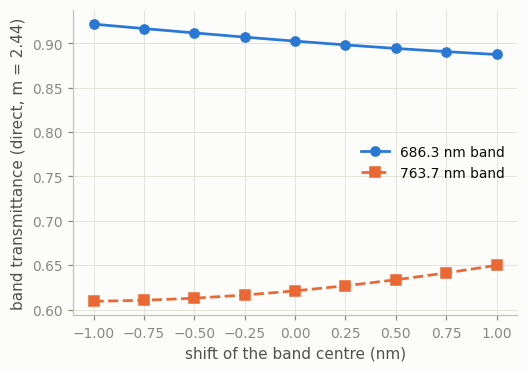

shift_nm,-1.00,-0.75,-0.50,-0.25,0.00,0.25,0.50,0.75,1.00
686.3,0.922,0.917,0.912,0.907,0.903,0.898,0.894,0.891,0.888
763.7,0.609,0.610,0.613,0.616,0.621,0.627,0.634,0.641,0.650


In [5]:
t_lbl = o2(gt_lbl, 'dir', 0.1)
shifts = np.arange(-1.0, 1.01, 0.25)
rows = []
for sh in shifts:
    rows.append(dict(shift_nm=sh, **{f'{b:.1f}': bands.average(t_lbl, gas.wl.values, [b + sh])[0] for b in (686.32, 763.70)}))
sens = pd.DataFrame(rows).set_index('shift_nm')
fig, ax = plt.subplots(figsize=(5.2, 3.6))
for i, c in enumerate(sens.columns):
    ax.plot(sens.index, sens[c], **ct.series(i), label=f'{c} nm band')
ax.set_xlabel('shift of the band centre (nm)'); ax.set_ylabel('band transmittance (direct, m = 2.44)')
ax.legend(loc='best'); plt.show()
sens.T

A shift of 0.25 nm changes the band transmittance by about 1 % (O2-A: 0.616-0.627 around 0.621; O2-B: 0.898-0.907),
a shift of 1 nm by 2-5 %. The comparison of transmittance models with image data in the O2 bands at the percent level
needs the spectral calibration of the sensor to a few tenths of a nanometre.

## 4. O2 features in the products

Band depth of $R_{rs}$ (band minus the linear continuum of its neighbours, median of the scene), products of hGRS 1.2.0
(`previous_behavior`) and 2.0.0 (see notebook 2 and `coupling_products.py`):

In [6]:
prod = pd.read_csv('coupling_products_metrics.csv').set_index(['scene', 'mode'])
cols = ['depth 686.3', 'depth 693.0', 'depth 763.7']
prod[cols].style.format('{:.2e}')

## Summary and options

* REPTRAN makes the O2 bands too deep at EnMAP resolution; $\kappa$ = 0.35 compensates on average, between the
  transmittance of the path reflectance and that of the surface term.
* The line-by-line O2 with the path-length model (`o2_model: lbl`, `gas_coupling: path_length`) reproduces the SOS-ABS
  transmittance of each term.
* In the products of the two EnMAP scenes (2.0.0: line by line in O2-B, REPTRAN with the path-length model and
  $\kappa$ = 1 in O2-A), the O2-A residual at 764 nm drops from -5.0e-4 to -5e-5 and from -8.8e-4 to -9e-5 sr$^{-1}$;
  the O2-B residual at 686 nm goes from +8e-5 to -1.0e-4 and from +7e-5 to -1.4e-4 sr$^{-1}$ (slightly over-corrected).
  On both scenes the AOT stays at its lower bound, because the VNIR reflectance of dark water is below the Rayleigh
  reflectance in the near infrared (notebook 2), not because of the TOA LUT.

Options:

1. estimate the spectral shift of the O2-A band per scene (fit of the band depth over bright pixels) and use it in the
   band responses of the gaseous transmittance;
2. look at the small over-correction of the O2-B band (686, 693 nm) once the AOT is retrieved.